# 13. Anomaly detection on network metrics (Week 4)

**Owner:** Rishi (Anomaly detection lead)

**Question:** do the market's network metrics behave unusually *before* the labeled stress episodes?

**Input:** `data/processed/features/connectedness_60d.parquet` from notebook 04 (60-day windows every 5 trading days: average correlation, PC1 share, absorption ratio). If Brandon's `data/processed/network_features.parquet` exists, its network density is added too.

**Method** (code in `src/anomaly.py`, tests in `tests/test_anomaly_alerts.py`):
1. **Trailing z-scores.** Each metric, and the 20-day change in average correlation and absorption, is compared with its previous year of values. The current value is not part of its own baseline. A metric fires at z >= 2 in the stress direction.
2. **Walk-forward Isolation Forest** (Liu, Ting and Zhou, 2008) on the same z-scores. It is first fitted on about three years of history, then refitted once a year on past data only. A row is flagged when its score is above the 95th percentile of the training scores. Isolation Forest also flags unusually *calm* markets, so its flags are only kept when the z-score composite points toward stress.
3. **Alert** = either detector fires.

Nothing here uses data from after the date it is reported on. The stress labels are only used at the end, to see whether the alerts came before episodes.

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Works from the repo root or from notebooks/. RGBFS_DATA_ROOT is only for test runs on fake data.
CODE_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "anomaly.py").exists())
DATA_ROOT = Path(os.environ.get("RGBFS_DATA_ROOT", CODE_ROOT))
sys.path.insert(0, str(CODE_ROOT))

from src import anomaly as an
from src import alerts as al

PROC = DATA_ROOT / "data" / "processed"
FEATURES = PROC / "features"
EPISODES_CSV = DATA_ROOT / "docs" / "stress_periods.csv"
OUT = DATA_ROOT / "notebooks" / "outputs" / "rishi_week4"
OUT.mkdir(parents=True, exist_ok=True)
print("Code:", CODE_ROOT)
print("Data:", DATA_ROOT)

Code: /home/claude/rgbfs
Data: /home/claude/rgbfs


In [2]:
def shade_episodes(ax, episodes, color="tab:red", alpha=0.12):
    for _, ep in episodes.iterrows():
        ax.axvspan(ep.start, ep.end, color=color, alpha=alpha, lw=0)

## 1. Load the network metrics

In [3]:
conn = pd.read_parquet(FEATURES / "connectedness_60d.parquet").sort_index()
conn.index = pd.to_datetime(conn.index)
base_cols = ["avg_corr", "pc1_share", "absorption"]

net_path = PROC / "network_features.parquet"
if net_path.exists():
    net = pd.read_parquet(net_path)
    if "date" in net.columns:
        net = net.set_index("date")
    net.index = pd.to_datetime(net.index)
    # Brandon's table is weekly (Fridays). Attach the latest value on or before each window date.
    merged = pd.merge_asof(conn.reset_index().rename(columns={conn.index.name or "index": "date"}).sort_values("date"),
                           net[["network_density"]].sort_index().reset_index().rename(columns={net.index.name or "index": "date"}),
                           on="date", direction="backward", tolerance=pd.Timedelta("7D"))
    conn = merged.set_index("date")
    base_cols.append("network_density")
    print("Added Brandon's network_density")
else:
    print("network_features.parquet not found; using connectedness metrics only")

episodes = al.load_episodes(EPISODES_CSV)
print(conn.shape, conn.index.min().date(), "to", conn.index.max().date())
conn[base_cols].describe().round(3)

Added Brandon's network_density
(1086, 5) 2005-04-06 to 2026-10-28


,avg_corr,pc1_share,absorption,network_density
count,1086.000,1086.000,1086.000,1086.000
mean,0.323,0.356,0.685,0.166
std,0.133,0.124,0.075,0.191
min,0.068,0.114,0.532,0.008
25%,0.222,0.262,0.630,0.041
50%,0.318,0.349,0.673,0.098
75%,0.394,0.420,0.731,0.199
max,0.723,0.731,0.929,0.937


## 2. Run both detectors

In [4]:
res = an.detect(conn, base_cols=base_cols)
print("Rows:", len(res))
print("z-score flag rate:     ", round(res.z_flag.mean(), 3))
print("Isolation Forest rate: ", round(res.if_flag.mean(), 3), "(any direction)")
print("IF, stress direction:  ", round(res.if_flag_stress.mean(), 3))
print("Combined alert rate:   ", round(res.alert.mean(), 3))
print("First z-score:", res.z_composite.first_valid_index().date(), " First IF score:", res.if_score.first_valid_index().date())

Rows: 1086
z-score flag rate:      0.174
Isolation Forest rate:  0.043 (any direction)
IF, stress direction:   0.032
Combined alert rate:    0.174
First z-score: 2005-10-10  First IF score: 2008-12-12


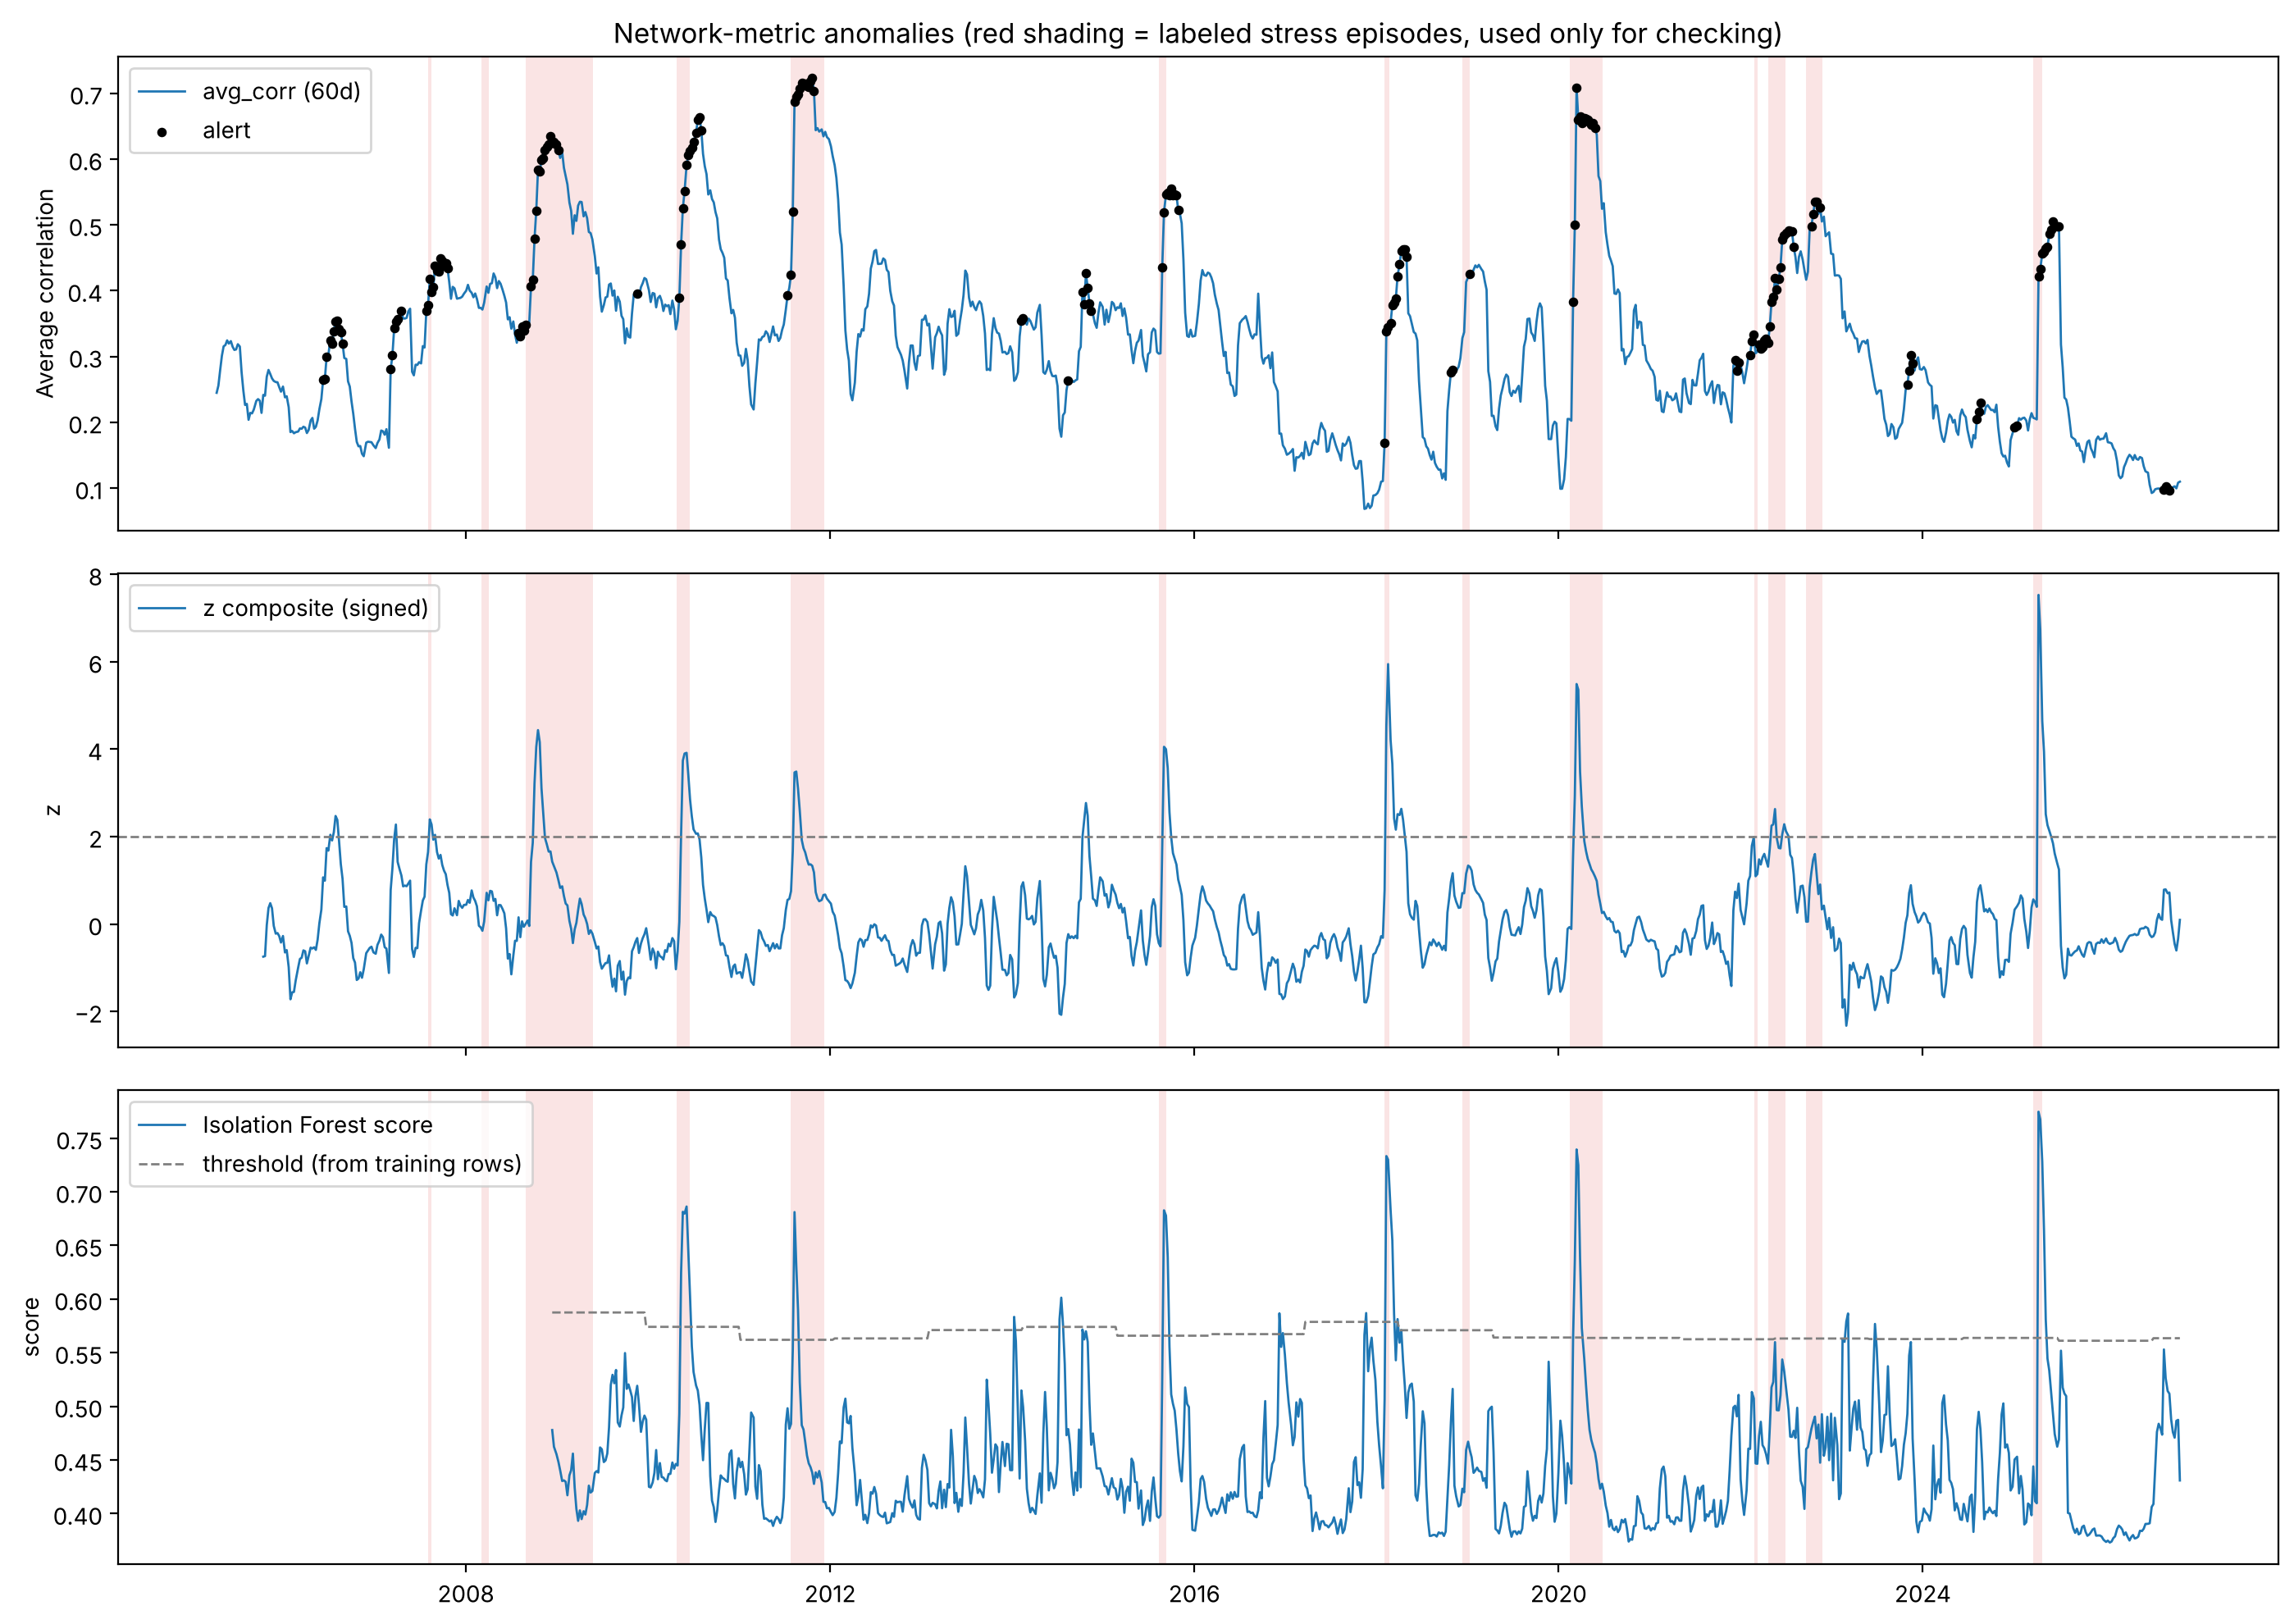

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
ax = axes[0]
ax.plot(conn.index, conn.avg_corr, lw=1, label="avg_corr (60d)")
hit = res.index[res.alert.eq(1)]
ax.scatter(hit, conn.loc[hit, "avg_corr"], s=10, color="black", label="alert", zorder=3)
ax.set_ylabel("Average correlation"); ax.legend(loc="upper left")
ax = axes[1]
ax.plot(res.index, res.z_composite, lw=1, label="z composite (signed)")
ax.axhline(an.Z_THRESHOLD, ls="--", color="gray", lw=1)
ax.set_ylabel("z"); ax.legend(loc="upper left")
ax = axes[2]
ax.plot(res.index, res.if_score, lw=1, label="Isolation Forest score")
ax.plot(res.index, res.if_threshold, lw=1, ls="--", color="gray", label="threshold (from training rows)")
ax.set_ylabel("score"); ax.legend(loc="upper left")
for a in axes:
    shade_episodes(a, episodes)
axes[0].set_title("Network-metric anomalies (red shading = labeled stress episodes, used only for checking)")
plt.tight_layout()
plt.savefig(OUT / "anomaly_timeline.png", dpi=120)
plt.show()

## 3. Did alerts come before the episodes?

An episode counts as **warned** if the first alert is in the 60 trading days before its start (and after the previous episode ended). **Late** means the first alert came in the first 10 days after the start. Both start dates from the stress labels are checked: `start` (centered volatility, the early bound) and `start_trailing` (the late bound).

Alerts are moved onto the trading-day calendar first. A window value dated *t* is used from *t* until the next window arrives (5 trading days later).

In [6]:
calendar = pd.read_parquet(PROC / "daily_panel.parquet").index
calendar = pd.DatetimeIndex(calendar).sort_values()
daily = an.to_daily(res.drop(columns=["fit_end"]), calendar)
signals = {"combined": daily.alert, "z-score only": daily.z_flag, "IF (stress direction)": daily.if_flag_stress}
summary = pd.DataFrame([al.summarize_signal(name, s, episodes, start_col=col)
                        for col in ["start", "start_trailing"] for name, s in signals.items()])
summary.round(3)

,signal,start_col,episodes_scored,warned_early,late,missed,median_lead_days,alert_events,false_alarm_events,false_alarms_per_year,day_days,day_flag_rate,day_precision,day_recall,day_false_alarm_rate
0,combined,start,13,8,4,1,27.5,29,12,0.570,4646,0.118,0.113,0.238,0.111
1,z-score only,start,13,8,4,1,27.5,29,12,0.570,4646,0.118,0.113,0.238,0.111
2,IF (stress direction),start,10,0,1,9,NaN,8,2,0.112,3951,0.014,0.000,0.000,0.015
3,combined,start_trailing,13,12,0,1,24.5,29,14,0.665,4775,0.125,0.146,0.335,0.113
4,z-score only,start_trailing,13,12,0,1,24.5,29,14,0.665,4775,0.125,0.146,0.335,0.113
5,IF (stress direction),start_trailing,10,1,5,4,3.0,8,2,0.112,4050,0.015,0.051,0.015,0.015


In [7]:
lt = al.lead_times(daily.alert, episodes)
lt[["episode_id", "name", "start", "first_alert", "lead_days", "already_on", "result"]]

,episode_id,name,start,first_alert,lead_days,already_on,result
0,1,Aug 2007 credit and quant-fund stress,2007-08-03,2007-07-26,6.0,False,early
1,2,Bear Stearns,2008-03-04,NaT,NaN,False,missed
2,3,Global financial crisis (Lehman),2008-08-29,2008-07-30,22.0,False,early
3,4,Flash crash and first euro-area debt stress,2010-04-26,2010-05-06,-8.0,False,late
4,5,"U.S. debt ceiling, S&P downgrade and euro-area...",2011-07-25,2011-07-14,7.0,False,early
5,6,China devaluation selloff,2015-08-12,2015-08-25,-9.0,False,late
6,7,Feb 2018 volatility spike,2018-02-01,2018-02-02,-1.0,False,late
7,8,Q4 2018 selloff,2018-12-11,2018-10-26,30.0,False,early
8,9,COVID-19 crash,2020-02-14,2020-02-28,-9.0,False,late
9,10,Russia's invasion of Ukraine,2022-02-23,2021-12-09,51.0,False,early


## 4. Sensitivity to the two thresholds

A lower bar warns earlier but raises more false alarms. This grid shows the trade-off so the threshold is chosen on purpose, not by default. **Do not pick the best row and report it as the result:** that would be tuning on the same 13 episodes we evaluate on. Report the default (z = 2, 95th percentile) and show this table as a robustness check.

In [8]:
rows = []
for z_thr in [1.5, 2.0, 2.5]:
    for q in [0.90, 0.95, 0.99]:
        r = an.detect(conn, base_cols=base_cols, z_threshold=z_thr, if_kwargs={"quantile": q})
        d = an.to_daily(r[["alert"]], calendar)
        s = al.summarize_signal(f"z>={z_thr}, IF q={q}", d.alert, episodes)
        rows.append({"z_threshold": z_thr, "if_quantile": q, **{k: s[k] for k in
                     ["warned_early", "late", "missed", "median_lead_days", "false_alarms_per_year", "day_precision", "day_recall"]}})
sens = pd.DataFrame(rows)
sens.round(3)

,z_threshold,if_quantile,warned_early,late,missed,median_lead_days,false_alarms_per_year,day_precision,day_recall
0,1.5,0.90,10,3,0,31.5,0.855,0.098,0.327
1,1.5,0.95,10,3,0,31.5,0.855,0.098,0.327
2,1.5,0.99,10,3,0,31.5,0.855,0.098,0.327
3,2.0,0.90,8,4,1,27.5,0.570,0.113,0.238
4,2.0,0.95,8,4,1,27.5,0.570,0.113,0.238
5,2.0,0.99,8,4,1,27.5,0.570,0.113,0.238
6,2.5,0.90,5,5,3,25.0,0.428,0.054,0.073
7,2.5,0.95,5,4,4,25.0,0.428,0.054,0.073
8,2.5,0.99,5,4,4,25.0,0.428,0.054,0.073


## 5. Save outputs

* `data/processed/features/anomaly_network_daily.parquet`: daily anomaly scores and flags for modeling (Week 5) and the dashboard (Week 7). Large, so it goes in the shared Drive `data/processed/features/` folder, not GitHub.
* `notebooks/outputs/rishi_week4/`: small summary tables and the chart.

In [9]:
daily_out = daily.drop(columns=[c for c in ["if_threshold"] if c in daily.columns])
daily_out.to_parquet(FEATURES / "anomaly_network_daily.parquet")
res.to_csv(OUT / "anomaly_scores_by_window.csv")
summary.to_csv(OUT / "signal_summary.csv", index=False)
lt.to_csv(OUT / "lead_times_combined.csv", index=False)
sens.to_csv(OUT / "threshold_sensitivity.csv", index=False)
al.score_events(daily.alert, episodes).to_csv(OUT / "alert_events.csv", index=False)
print("Saved", FEATURES / "anomaly_network_daily.parquet", daily_out.shape)

Saved /home/claude/rgbfs/data/processed/features/anomaly_network_daily.parquet (6997, 14)


## 6. Findings (real data; rerun 2026-11-21)

**Update 2026-11-21 (absorption fix).** The first run (2026-11-18) used an absorption ratio that was stuck at about 1.0: a 60-day window has at most 59 non-zero eigenvalues, while the formula took one fifth of about 400 stocks (about 80 components). `src/windows.py` now takes one fifth of the window's rank (about 12 components), so absorption moves between about 0.53 and 0.93. The fix was made because the measure was mathematically degenerate, not to improve results. First run vs. now, using `start`: network alert 5 early, 4 late, 4 missed, 1.14 false alarms per year → 8 early, 4 late, 1 missed, 0.57 per year. Brandon's network density (merged when `network_features.parquet` exists) does not change the result; the fixed absorption ratio does (checked by running each variant).

Using the `start` dates (13 episodes):
* **Early (8):** Aug 2007 (6 trading days ahead), Lehman (22), 2011 debt ceiling (7), Q4 2018 (30), Ukraine 2022 (51), both 2022 rate-hike legs (25 and 56) and the 2025 tariff selloff (51). The 2022 second leg is `already_on` (the alert was still on from the first leg), so it is not a clean warning.
* **Late (4):** 2010 flash crash, 2015, Feb 2018 and COVID, 1 to 9 trading days after the start.
* **Missed (1):** Bear Stearns, which came while correlation was already high from Aug 2007, so the one-year baseline was high.

With `start_trailing` (up to about 10 days later): 12 early, 0 late, 1 missed, but several of those warnings are only a few days ahead of the later start.

**Cost:** 12 of 29 alert events were false alarms (0.57 per year), but the alert is on for 11.8% of days, so when it fires it tends to stay on. Day-level precision is 11.3% against a base rate of about 5%.

**Isolation Forest adds nothing:** in the stress direction it fired in 8 events and warned no episode early. The combined alert equals the z-score alert.

**Thresholds (Section 4):** z ≥ 1.5 warns 10 early with no misses but 0.86 false alarms per year; z ≥ 2.5 warns only 5. The default (z = 2) was fixed before the results and is kept; the grid is a robustness check, not a tuning step.